In [ ]:
import pandas as pd

In [ ]:
monthly = pd.read_csv('/content/nyiso_fuel_mix_monthly_2023_2025.csv')
monthly

,year,month,month_name,season,natural_gas_mwh,dual_fuel_mwh,nuclear_mwh,hydro_mwh,wind_mwh,other_renewables_mwh,other_fossil_mwh,total_mwh
0,2023,1,Jan,Winter,2647071,2230614,2471425,2515014,317117,178484,6363,10366088
1,2023,2,Feb,Winter,1965276,2518621,2187373,2166940,520180,136344,20012,9514746
2,2023,3,Mar,Spring,1829051,2362288,2143697,2349213,489949,162649,11565,9348412
3,2023,4,Apr,Spring,1794058,2063199,1772552,2231050,447304,147844,3504,8459511
4,2023,5,May,Spring,1914483,2250960,2458572,2300320,330457,204641,2064,9461497
5,2023,6,Jun,Summer,2605558,3063486,2374817,2028916,214409,194917,2911,10485014
6,2023,7,Jul,Summer,3632059,4699530,2394760,2316127,233107,207995,47932,13531510
7,2023,8,Aug,Summer,2850572,3679112,2416121,2344227,298609,212962,20384,11821987
8,2023,9,Sep,Fall,2651427,3243836,2117568,2113718,213372,198219,32435,10570575
9,2023,10,Oct,Fall,2287306,2332811,2399656,2157302,450958,190985,9444,9828462


In [ ]:
monthly.dtypes

,0
year,int64
month,int64
month_name,object
season,object
natural_gas_mwh,int64
dual_fuel_mwh,int64
nuclear_mwh,int64
hydro_mwh,int64
wind_mwh,int64
other_renewables_mwh,int64


In [ ]:
monthly.isnull().sum()

,0
year,0
month,0
month_name,0
season,0
natural_gas_mwh,0
dual_fuel_mwh,0
nuclear_mwh,0
hydro_mwh,0
wind_mwh,0
other_renewables_mwh,0


In [ ]:
data_2023 = monthly[monthly['year'] == 2023]
data_2023

,year,month,month_name,season,natural_gas_mwh,dual_fuel_mwh,nuclear_mwh,hydro_mwh,wind_mwh,other_renewables_mwh,other_fossil_mwh,total_mwh
0,2023,1,Jan,Winter,2647071,2230614,2471425,2515014,317117,178484,6363,10366088
1,2023,2,Feb,Winter,1965276,2518621,2187373,2166940,520180,136344,20012,9514746
2,2023,3,Mar,Spring,1829051,2362288,2143697,2349213,489949,162649,11565,9348412
3,2023,4,Apr,Spring,1794058,2063199,1772552,2231050,447304,147844,3504,8459511
4,2023,5,May,Spring,1914483,2250960,2458572,2300320,330457,204641,2064,9461497
5,2023,6,Jun,Summer,2605558,3063486,2374817,2028916,214409,194917,2911,10485014
6,2023,7,Jul,Summer,3632059,4699530,2394760,2316127,233107,207995,47932,13531510
7,2023,8,Aug,Summer,2850572,3679112,2416121,2344227,298609,212962,20384,11821987
8,2023,9,Sep,Fall,2651427,3243836,2117568,2113718,213372,198219,32435,10570575
9,2023,10,Oct,Fall,2287306,2332811,2399656,2157302,450958,190985,9444,9828462


In [ ]:
mwh_cols = [col for col in monthly.columns if col.endswith('_mwh') and col != 'total_mwh']
total_by_source = monthly[mwh_cols].sum()
grand_total = total_by_source.sum()

summary_df = pd.DataFrame({
    'energy_source': total_by_source.index,
    'percentage': (total_by_source / grand_total) * 100
}).reset_index(drop=True)

summary_df

,energy_source,percentage
0,natural_gas_mwh,24.374828
1,dual_fuel_mwh,27.271309
2,nuclear_mwh,21.392336
3,hydro_mwh,20.162795
4,wind_mwh,4.609696
5,other_renewables_mwh,2.055482
6,other_fossil_mwh,0.133555


In [ ]:
summary_df['energy_source'] = summary_df['energy_source'].replace(
    {'natural_gas_mwh': 'Natural Gas',
   'dual_fuel_mwh': 'Dual Fuel',
   'nuclear_mwh': 'Nuclear',
   'hydro_mwh' : 'Hydro',
   'wind_mwh' : "Wind",
   'other_renewables_mwh' : 'Other Renewable Res.',
   'other_fossil_mwh' : 'Other Fossil Fuels'})

In [ ]:
summary_df

,energy_source,percentage
0,Natural Gas,24.374828
1,Dual Fuel,27.271309
2,Nuclear,21.392336
3,Hydro,20.162795
4,Wind,4.609696
5,Other Renewable Res.,2.055482
6,Other Fossil Fuels,0.133555


In [ ]:
summary_df['energy_source'] = summary_df['energy_source'].replace(
    {'Other Renewable' : 'Other Renewable Res.'})

In [ ]:
summary_df

,energy_source,percentage
0,Natural Gas,24.374828
1,Dual Fuel,27.271309
2,Nuclear,21.392336
3,Hydro,20.162795
4,Wind,4.609696
5,Other Renewable Res.,2.055482
6,Other Fossil Fuels,0.133555


In [ ]:
summary_df['percentage'].sum()

np.float64(100.0)

In [ ]:
summary_df['percentage'] = summary_df['percentage'].round(2)

In [ ]:
summary_df

,energy_source,percentage
0,Natural Gas,24.37
1,Dual Fuel,27.27
2,Nuclear,21.39
3,Hydro,20.16
4,Wind,4.61
5,Other Renewable Res.,2.06
6,Other Fossil Fuels,0.13


In [ ]:
summary_df.to_csv('energy_total_2023.csv', index=False)

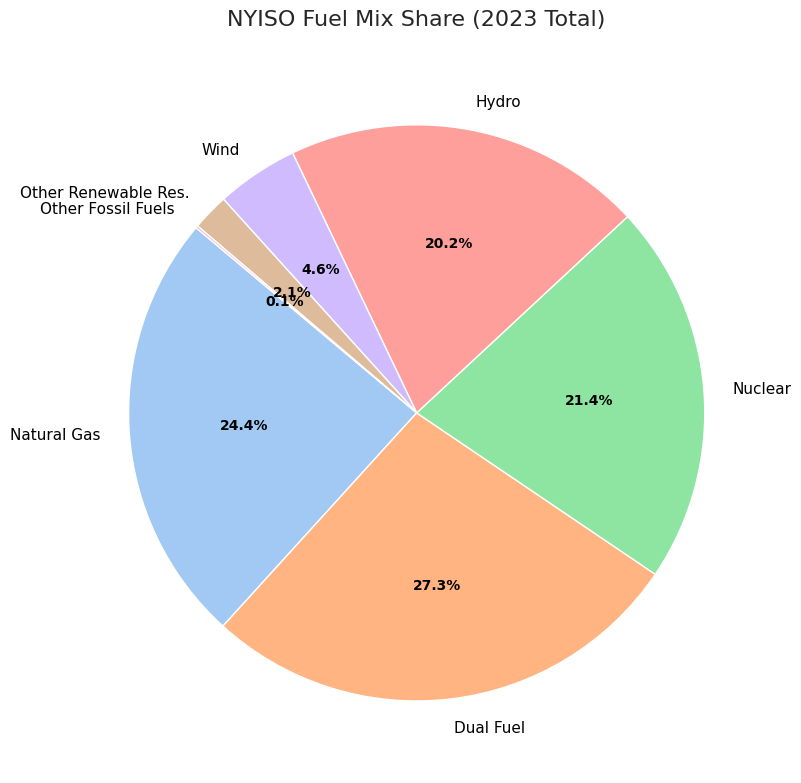

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style and colors
sns.set_theme(style="whitegrid")
colors = sns.color_palette("pastel")[0:len(summary_df)]

# Create a pie chart
fig, ax = plt.subplots(figsize=(10, 8))
wedges, texts, autotexts = ax.pie(
    summary_df['percentage'],
    labels=summary_df['energy_source'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops=dict(color="black")
)

# Style percentages text
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_weight('bold')

ax.set_title('NYISO Fuel Mix Share (2023 Total)', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact

# Prepare the data
mwh_cols = [col for col in monthly.columns if col.endswith('_mwh') and col != 'total_mwh']
friendly_names = {
    'natural_gas_mwh': 'Natural Gas',
    'dual_fuel_mwh': 'Dual Fuel',
    'nuclear_mwh': 'Nuclear',
    'hydro_mwh': 'Hydro',
    'wind_mwh': 'Wind',
    'other_renewables_mwh': 'Other Renewable Res.',
    'other_fossil_mwh': 'Other Fossil Fuels'
}

# Create chronological month labels (e.g., '2023-01')
monthly['date_label'] = monthly['year'].astype(str) + '-' + monthly['month'].astype(str).str.zfill(2)

# Base dataframes for the two views
# Convert MWh to TWh (1 TWh = 1,000,000 MWh)
df_twh = monthly[mwh_cols].rename(columns=friendly_names) / 1e6
df_twh.index = monthly['date_label']

# Percentage share dataframe
df_pct = monthly[mwh_cols].rename(columns=friendly_names).div(monthly['total_mwh'], axis=0) * 100
df_pct.index = monthly['date_label']

def plot_stacked_chart(view_type):
    fig, ax = plt.subplots(figsize=(16, 8))
    sns.set_theme(style="whitegrid")

    if view_type == 'TWh':
        df_twh.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')
        ax.set_ylabel('Generation (TWh)', fontsize=12)
        ax.set_title('NYISO Monthly Fuel Mix (TWh)', fontsize=16, pad=15)
    else:
        df_pct.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')
        ax.set_ylabel('Generation Share (%)', fontsize=12)
        ax.set_title('NYISO Monthly Fuel Mix Share (%)', fontsize=16, pad=15)
        ax.set_ylim(0, 100)

    ax.set_xlabel('Month (YYYY-MM)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Energy Source', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# Interactive dropdown switch
interact(plot_stacked_chart, view_type=widgets.Dropdown(options=['TWh', '% Share'], value='TWh', description='View Mode:'))

interactive(children=(Dropdown(description='View Mode:', options=('TWh', '% Share'), value='TWh'), Output()), …

<function __main__.plot_stacked_chart(view_type)>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact
import numpy as np

# Group the monthly data by year
yearly_mwh = monthly.groupby('year')[mwh_cols].sum()
yearly_total = monthly.groupby('year')['total_mwh'].sum()

# Prepare DataFrames for TWh and % Share views
df_yearly_twh = yearly_mwh.rename(columns=friendly_names) / 1e6
df_yearly_pct = yearly_mwh.rename(columns=friendly_names).div(yearly_total, axis=0) * 100

def plot_yearly_stacked_chart(view_type):
    fig, ax = plt.subplots(figsize=(12, 8))
    sns.set_theme(style="whitegrid")

    if view_type == 'TWh':
        df_yearly_twh.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')
        ax.set_ylabel('Generation (TWh)', fontsize=12)
        ax.set_title('NYISO Yearly Fuel Mix (TWh)', fontsize=16, pad=15)

        # Add text labels
        for c in ax.containers:
            labels = [f'{v.get_height():.1f} TWh' if v.get_height() > 1.5 else '' for v in c]
            ax.bar_label(c, labels=labels, label_type='center', fontsize=9, fontweight='bold')
    else:
        df_yearly_pct.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')
        ax.set_ylabel('Generation Share (%)', fontsize=12)
        ax.set_title('NYISO Yearly Fuel Mix Share (%)', fontsize=16, pad=15)
        ax.set_ylim(0, 105)

        # Add text labels
        for c in ax.containers:
            labels = [f'{v.get_height():.1f}%' if v.get_height() > 1.5 else '' for v in c]
            ax.bar_label(c, labels=labels, label_type='center', fontsize=9, fontweight='bold')

    ax.set_xlabel('Year', fontsize=12)
    plt.xticks(rotation=0)
    plt.legend(title='Energy Source', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# Interactive dropdown switch for yearly view
interact(plot_yearly_stacked_chart, view_type=widgets.Dropdown(options=['TWh', '% Share'], value='TWh', description='View Mode:'))

interactive(children=(Dropdown(description='View Mode:', options=('TWh', '% Share'), value='TWh'), Output()), …

<function __main__.plot_yearly_stacked_chart(view_type)>

In [ ]:
# Prepare the data
mwh_cols = [col for col in monthly.columns if col.endswith('_mwh') and col != 'total_mwh']
friendly_names = {
    'natural_gas_mwh': 'Natural Gas',
    'dual_fuel_mwh': 'Dual Fuel',
    'nuclear_mwh': 'Nuclear',
    'hydro_mwh': 'Hydro',
    'wind_mwh': 'Wind',
    'other_renewables_mwh': 'Other Renewable Res.',
    'other_fossil_mwh': 'Other Fossil Fuels'
}